# K-Nearest Neighbors and Decision Trees for Regression

Before we implement models using scikit-learn, let's think conceptually about the $k$-nearest neighbors and decision tree algorithms for regression.

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

## Visualizing K-Nearest Neighbors Regression Functions

A predictive model is simply a function $f$ that maps feature values ${\bf x}$ to target values $y$. We can visualize $f$ when ${\bf x}$ consists of just a single feature. We have seen that a linear regression function $f$ based on a single feature $x$ is a linear function of $x$. What does $f$ look like when the model is a $k$-nearest neighbors regressor?


### K-Nearest Neighbors Regression Functions for a Single Quantitative Feature: Wine Data


Recall the wines data set where our target is log(price), a proxy for quality.
We'll use a K-Nearest Neighbors model for predicting log(price) from a single feature, age.

First, we extract the training data. There is no need to scale the features in this case because there is only one feature. (The point of scaling is to bring all of the *feature* variables to the same scale before computing distances between observations.)

In [2]:
bordeaux_df = pd.read_csv("https://dlsun.github.io/pods/data/bordeaux.csv",
                          index_col="year")

# Split the data into training and test sets
bordeaux_train = bordeaux_df.loc[:1980].copy()
bordeaux_test = bordeaux_df.loc[1981:].copy()

# Log transform the target
bordeaux_train["log(price)"] = np.log(bordeaux_train["price"])

# train on a single feature, age
X_train = bordeaux_train[["age"]]
y_train = bordeaux_train["log(price)"]

In [3]:
bordeaux_train[["age", "log(price)"]].sort_values("age").head(5)

,age,log(price)
year,,
1980,12,2.639057
1979,13,3.044522
1978,14,3.295837
1977,15,2.397895
1976,16,3.218876


Let's make a scatterplot of the training data. Careful! In the reading, we made several scatterplots where both the x-axis and y-axis corresponded to *feature* variables (and the target corresponded to color). But now the x-axis is the feature and the y-axis is the target.

<Axes: xlabel='age', ylabel='log(price)'>

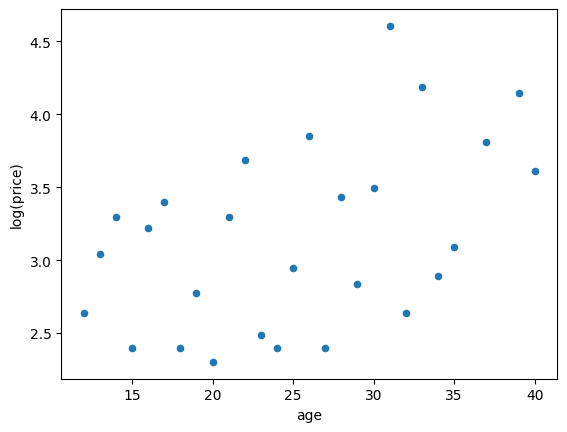

In [4]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

1. Consider a **1-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 13? age = 11.5? age = 12.49? age = 12.51? age = 13.49? age = 13.51?

**Sketch on paper and discuss with your partner.**



2. Consider a **2-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 12.99? age = 13.01? age = 13.99? age = 14.01?

**Sketch on paper and discuss with your partner.**

3. What would the 27-nearest neighbors regression function look like? **Discuss with your partner before proceeding.** Hint: what is special about 27 in this example?

**Sketch on paper and discuss with your partner.**

It would look like a flat line as it's an average of all the Y values.

4. Now we'll fit a K-nearest neighbors regression model and plot the regression function for K=1, 2, 10, 27. The code below basically implements the code from the previous part for each of the values of K. Run the code and **discuss the output with your partner**. Do the regression functions look like what you expected? What happens as K increases?

<Axes: xlabel='age', ylabel='log(price)'>

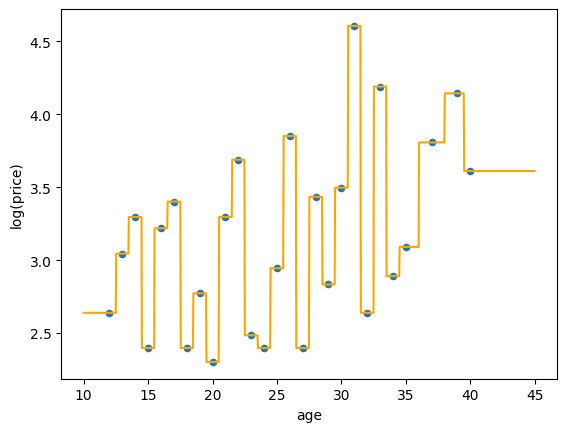

In [5]:
# 1-nearest neighbor model
from sklearn.neighbors import KNeighborsRegressor

# Fit k-nearest neighbors
model = KNeighborsRegressor(n_neighbors=1)
model.fit(X=X_train, y=y_train)

# Define a grid of feature values to make predictions for
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

# Make predictions at those feature values.
y_new_ = pd.Series(
    # ADD YOUR CODE HERE,
    model.predict(X_new),
    index=X_new["age"]
)

# Plot the scatter plot and the predictions (regression function)
bordeaux_train.plot.scatter(x="age", y="log(price)")
y_new_.plot.line(color = "orange")


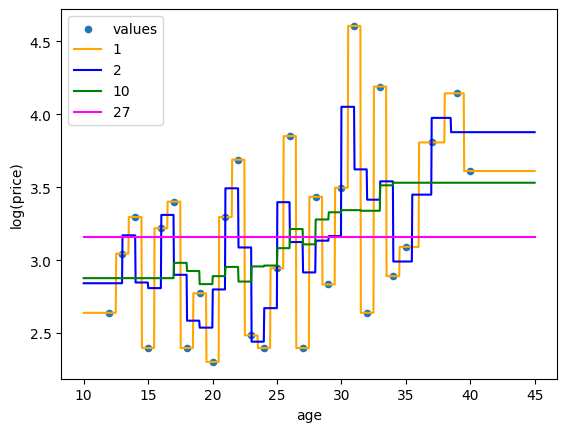

In [6]:
# k-nearest neighbors for several values of k
ks = [1, 2, 10, 27]
colors = ["orange", "blue", "green", "magenta", "black"]

bordeaux_train.plot.scatter(x="age", y="log(price)")

# Define a grid of feature values.
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

for i in range(len(ks)):

  # Fit k-nearest neighbors
  model = KNeighborsRegressor(n_neighbors=ks[i])
  model.fit(X=X_train, y=y_train)

  # Make predictions at those feature values.
  y_new_ = pd.Series(
      model.predict(X_new),
      index=X_new["age"]
  )

  # Plot the predictions.
  y_new_.plot.line(color = colors[i])
  plt.legend(["values"] + ks);


### K-Nearest Neighbors Regression Functions for a Single Categorical Feature: Housing Data

Recall the Ames housing data set. We'll use a single categorical feature---Neighborhood---to predict SalePrice.

In [7]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames[["Neighborhood", "SalePrice"]]

,Neighborhood,SalePrice
0,NAmes,215000
1,NAmes,105000
2,NAmes,172000
3,NAmes,244000
4,Gilbert,189900
...,...,...
2925,Mitchel,142500
2926,Mitchel,131000
2927,Mitchel,132000
2928,Mitchel,170000


We'll fit a **10-nearest neighbors** regression model to predict house price using **Neighborhood** as the only feature. Since Neighborhood is categorical we first need to convert it to dummies, using a `ColumnTransformer` and a `Pipeline`.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = df_ames[["Neighborhood"]]
y = df_ames["SalePrice"]

ct = ColumnTransformer(
    [("dummify", OneHotEncoder(), ["Neighborhood"])]
)

knn_model = Pipeline([
    ("preprocessing", ct),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_model.fit(X, y)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('dummify', OneHotEncoder(),
                                                  ['Neighborhood'])])),
                ('knn', KNeighborsRegressor(n_neighbors=10))])

Now we'll find the predicted price for each Neighborhood.

In [9]:
neighborhoods = pd.Series(df_ames["Neighborhood"].unique(), name="Neighborhood").to_frame()
neighborhoods["predicted"] = knn_model.predict(neighborhoods)
neighborhoods

,Neighborhood,predicted
0,NAmes,152100.0
1,Gilbert,185529.0
2,StoneBr,331155.9
3,NWAmes,180865.0
4,Somerst,176270.0
5,BrDale,102150.0
6,NPkVill,142280.0
7,NridgHt,267870.9
8,Blmngtn,211209.1
9,NoRidge,323750.0


Let's compare the predicted prices to the mean price for each neighborhood.

In [10]:
pd.merge(pd.merge(neighborhoods,
                  df_ames.groupby("Neighborhood")["SalePrice"].mean(), left_on = "Neighborhood", right_index = True),
         df_ames["Neighborhood"].value_counts(), left_on = "Neighborhood", right_index = True).sort_values("count")

,Neighborhood,predicted,SalePrice,count
27,Landmrk,133390.0,137000.000000,1
26,GrnHill,166640.0,280000.000000,2
12,Greens,181125.0,193531.250000,8
21,Blueste,143590.0,143590.000000,10
6,NPkVill,142280.0,140710.869565,23
25,Veenker,257420.0,248314.583333,24
8,Blmngtn,211209.1,196661.678571,28
5,BrDale,102150.0,105608.333333,30
24,MeadowV,107349.0,95756.486486,37
16,ClearCr,194430.0,208662.090909,44


 5. For what neighborhood is the predicted price equal to the neighborhood's mean price? Why? What is special about that neighborhood? Can you explain why the predicted prices don't match the mean price for the other neighborhoods?

**Discuss with your partner.**

### K-Nearest Neighbors Regression Functions for Two Quantitative Features: Sketching for Small Training Data

When there are multiple features, a regression function will be a surface in a higher dimensional space and is therefore difficult to visualize. Essentially the regression function splits the feature space into regions based on which $K$ points in the training data are closest, and makes constant predictions over these regions so that the regression surface has something like a ["log step"](https://i.pinimg.com/originals/f3/61/21/f36121c84fa42b6cad525f865d61d049.png) shape.

We'll sketch plots of the regression surface when there are two quantitative features and the training data only contains a few observations. Assume that the features have already been scaled and that Euclidean distance is used to determine nearest neighbors.

6. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 2 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.**

7. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.**

8. Consider **2-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.**

## Decision Trees

Back to the wine data. Suppose again that we want to predict log(price) based on just a single feature, age.

<Axes: xlabel='age', ylabel='log(price)'>

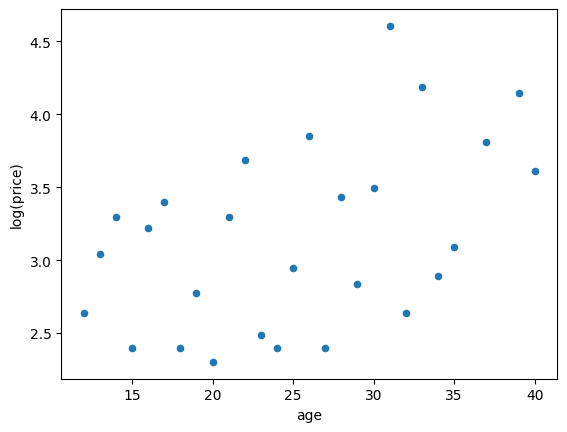

In [11]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

9. Suppose we use a regression decision tree with a single split at 20.5. Sketch a plot of what the regression function would look like.

**Sketch on paper and discuss with your partner.**

10. Suppose we use a decision tree with two splits at 20.5 and 30.5. Sketch a plot of what the regression function would look like.

**Sketch on paper and discuss with your partner.**

## Fitting KNN Regression Models with scikit-learn: Housing data

11. Fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a pipeline and column transformers as needed. Make a scatter plot of predicting price versus actual price.

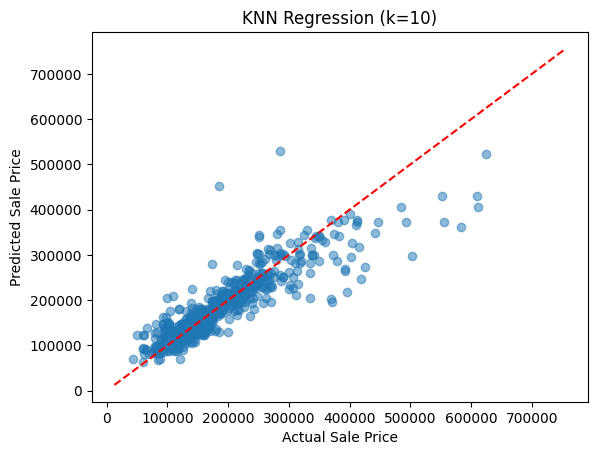

RMSE: 42529.967793177755


In [14]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

df_ames = pd.read_csv(
    "http://dlsun.github.io/pods/data/AmesHousing.txt",
    sep="\t"
)

X = df_ames[
    ["Gr Liv Area", "Bedroom AbvGr", "Full Bath",
     "Half Bath", "Neighborhood"]
]
y = df_ames["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

ct = ColumnTransformer([
    ("numeric", StandardScaler(),
     ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]),
    ("neighborhood", OneHotEncoder(handle_unknown="ignore"),
     ["Neighborhood"])
])

knn_model = Pipeline([
    ("preprocessing", ct),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

plt.scatter(y_test, knn_pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("KNN Regression (k=10)")
plt.show()

print("RMSE:", mean_squared_error(y_test, knn_pred) ** 0.5)

12. Repeat the previous part to fit a $k$-nearest neighbors model for some other value of $k$. Experiment with different values of $k$. (For this, you can just pick and choose a few, no need to automate it. We'll see how to do that later.) What value of $k$ seems to be "best"? How are you deciding?

In [15]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
for k in [3, 5, 10, 15, 20]:
    model = Pipeline([
        ("preprocessing", ct),
        ("knn", KNeighborsRegressor(n_neighbors=k))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rmse = mean_squared_error(y_test, predictions) ** 0.5

    print(f"k = {k}: RMSE = ${rmse:,.2f}")

k = 3: RMSE = $45,184.41
k = 5: RMSE = $42,470.67
k = 10: RMSE = $42,529.97
k = 15: RMSE = $43,649.65
k = 20: RMSE = $44,678.81


I tried a few different values of k and found that k = 5 performed best, with an RMSE of $42,470.67. I chose this value because it had the lowest prediction error on the test data.


13. Fit a regression decison tree that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a max depth of 4. Use a pipeline and column transformers as needed. Plot and interpret the tree. Also, make a scatter plot of predicting price versus actual price.

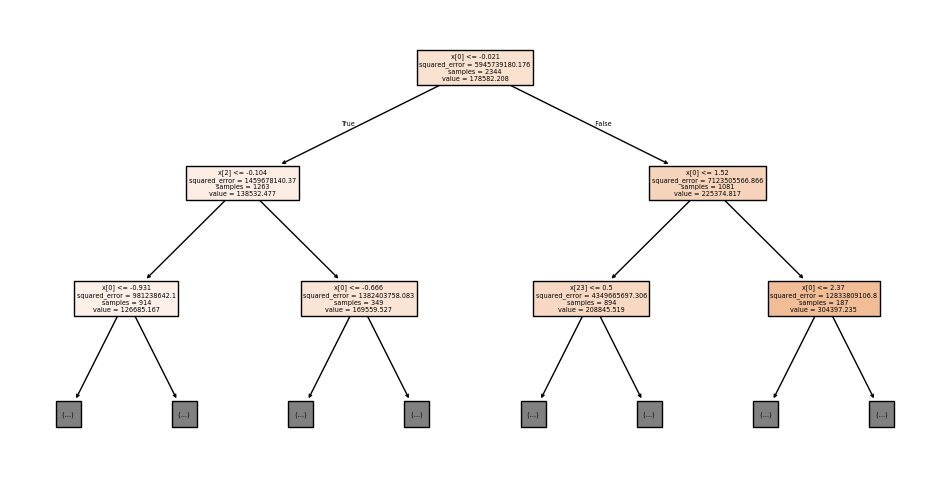

In [20]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
# Plot tree
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 6))
plot_tree(tree_model.named_steps["tree"], max_depth=2, filled=True)
plt.show()

The decision tree was fitted with a maximum depth of 4, but only the first two levels are displayed for readability. The tree splits homes based on their characteristics to estimate sale prices.

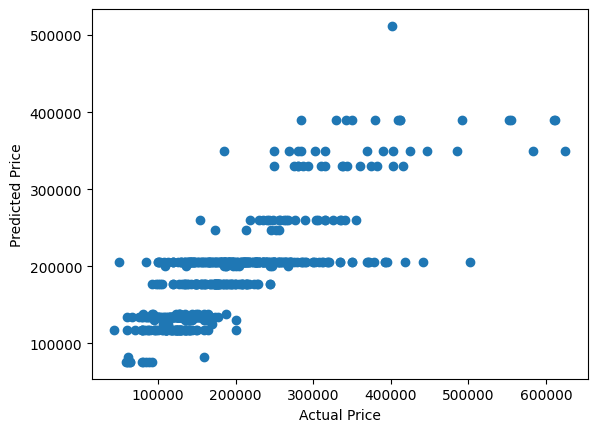

In [21]:
# Predicted vs Actual
predictions = tree_model.predict(X_test)

plt.scatter(y_test, predictions)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.show()

14. Repeat the previous part with different values of `max_depth`. What value of seems to be "best"? How are you deciding?

In [17]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
for depth in [2, 3, 4, 5, 6, 8, 10]:
    model = Pipeline([
        ("preprocessing", ct),
        ("tree", DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rmse = mean_squared_error(y_test, predictions) ** 0.5

    print(f"Depth = {depth}: RMSE = ${rmse:,.2f}")

Depth = 2: RMSE = $64,225.04
Depth = 3: RMSE = $61,394.54
Depth = 4: RMSE = $55,053.10
Depth = 5: RMSE = $50,890.65
Depth = 6: RMSE = $46,117.97
Depth = 8: RMSE = $43,936.63
Depth = 10: RMSE = $47,162.89


I tried several tree depths and found that max_depth = 8 performed best, with an RMSE of $43,936.63. I chose this depth because it had the lowest prediction error on the test data. Increasing the depth to 10 made the predictions less accurate.